# 00: Synthetic multi-view data (paper Section 5.1)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng_demo = np.random.default_rng(0)

In [2]:
def make_latents(setting, K, w, n, rng):
    """Return an (n, K) array of latent variables z."""
    mean = np.arange(K)
    if setting == "local":
        assert K % 2 == 0, "local setting pairs views, so K must be even"
        cov = np.kron(np.eye(K // 2), np.array([[1, w], [w, 1]]))
        return rng.multivariate_normal(mean, cov, size=n)
    if setting == "global":
        z = rng.normal(loc=mean, scale=1.0, size=(n, K))
        return (1 - w) * z + w * z[:, [0]]
    raise ValueError(setting)

In [3]:
for setting in ["local", "global"]:
    z = make_latents(setting, K=4, w=0.5, n=5000, rng=rng_demo)
    print(setting, "z shape:", z.shape)
    print("first 3 rows:\n", np.round(z[:3], 2))
    print("empirical correlation of latents:\n", np.round(np.corrcoef(z.T), 2), "\n")

local z shape: (5000, 4)
first 3 rows:
 [[-0.43  1.21  2.06  3.17]
 [-0.19  2.12  1.21  3.16]
 [ 0.92  1.3   3.08  4.12]]
empirical correlation of latents:
 [[ 1.    0.5  -0.01 -0.01]
 [ 0.5   1.   -0.01 -0.02]
 [-0.01 -0.01  1.    0.5 ]
 [-0.01 -0.02  0.5   1.  ]] 

global z shape: (5000, 4)
first 3 rows:
 [[0.32 1.23 1.23 1.95]
 [0.25 0.26 1.89 2.28]
 [0.94 0.3  1.48 1.64]]
empirical correlation of latents:
 [[1.   0.72 0.71 0.71]
 [0.72 1.   0.51 0.49]
 [0.71 0.51 1.   0.5 ]
 [0.71 0.49 0.5  1.  ]] 



In [4]:
def make_views(z, d, rng):
    """Map each latent column to a d-dimensional view with its own random tanh map."""
    n, K = z.shape
    views = []
    for k in range(K):
        W = rng.uniform(-1, 1, size=(1, d))
        views.append(np.tanh(z[:, [k]] @ W))
    return views

number of views: 4 | each view shape: (1000, 100)
view 0, sample 0, first 5 features: [ 0.016  0.013  0.003  0.039 -0.034]


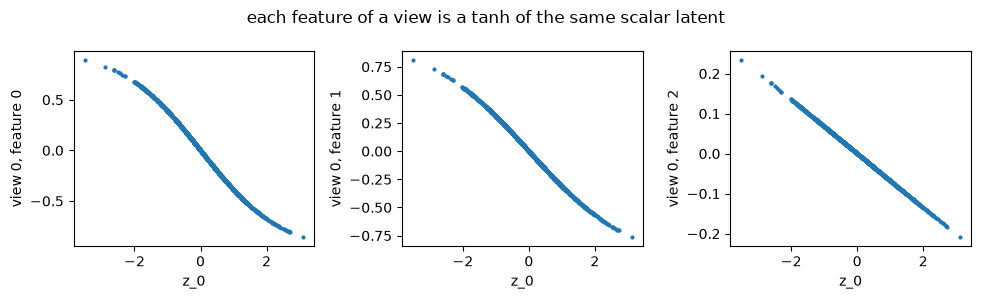

In [5]:
z = make_latents("local", K=4, w=0.5, n=1000, rng=rng_demo)
views = make_views(z, d=100, rng=rng_demo)
print("number of views:", len(views), "| each view shape:", views[0].shape)
print("view 0, sample 0, first 5 features:", np.round(views[0][0, :5], 3))

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, j in zip(axes, [0, 1, 2]):
    ax.scatter(z[:, 0], views[0][:, j], s=4)
    ax.set_xlabel("z_0"); ax.set_ylabel(f"view 0, feature {j}")
fig.suptitle("each feature of a view is a tanh of the same scalar latent")
plt.tight_layout(); plt.show()

In [6]:
def true_edges(setting, K, w):
    """K x K 0/1 matrix of which view pairs truly share information."""
    A = np.zeros((K, K))
    if w == 0:
        return A
    if setting == "local":
        for i in range(0, K, 2):
            A[i, i + 1] = A[i + 1, i] = 1
    else:  # global: all pairs share view 0's latent
        A[:] = 1
        np.fill_diagonal(A, 0)
    return A

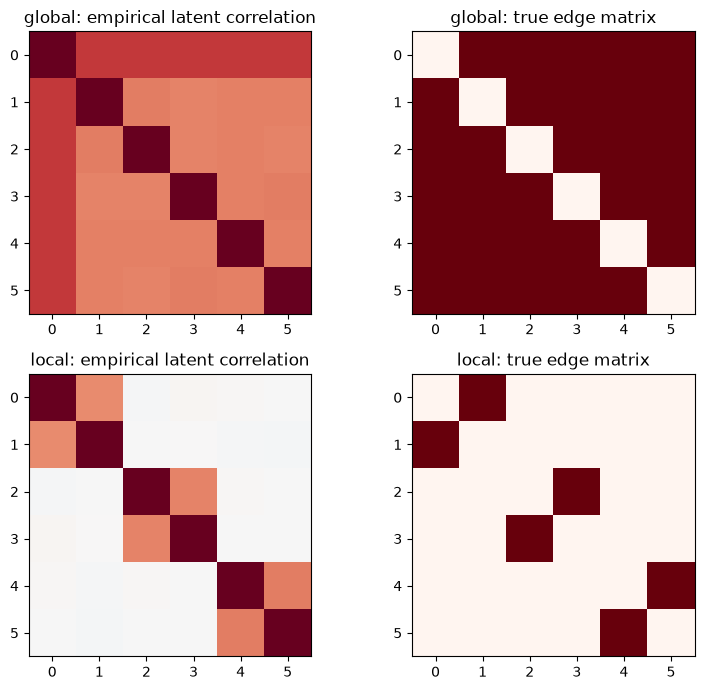

In [7]:
K, w = 6, 0.5
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for row, setting in enumerate(["global", "local"]):
    z = make_latents(setting, K, w, n=5000, rng=rng_demo)
    axes[row, 0].imshow(np.corrcoef(z.T), vmin=-1, vmax=1, cmap="RdBu_r")
    axes[row, 0].set_title(f"{setting}: empirical latent correlation")
    axes[row, 1].imshow(true_edges(setting, K, w), vmin=0, vmax=1, cmap="Reds")
    axes[row, 1].set_title(f"{setting}: true edge matrix")
for ax in axes.ravel():
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
plt.tight_layout(); plt.show()

In [8]:
def make_dataset(setting, K, w, n=1000, d=100, seed=0):
    rng = np.random.default_rng(seed)
    z = make_latents(setting, K, w, n, rng)
    views = make_views(z, d, rng)
    cut = int(0.8 * n)
    return {
        "views_unlab": [v[:cut] for v in views],
        "views_lab": [v[cut:] for v in views],
        "z_lab": z[cut:],
        "true_edges": true_edges(setting, K, w),
    }

In [9]:
ds = make_dataset("local", K=6, w=0.5, seed=0)
print({k: (len(v), v[0].shape) if isinstance(v, list) else v.shape for k, v in ds.items()})
print("true edges:\n", ds["true_edges"].astype(int))

{'views_unlab': (6, (800, 100)), 'views_lab': (6, (200, 100)), 'z_lab': (200, 6), 'true_edges': (6, 6)}
true edges:
 [[0 1 0 0 0 0]
 [1 0 0 0 0 0]
 [0 0 0 1 0 0]
 [0 0 1 0 0 0]
 [0 0 0 0 0 1]
 [0 0 0 0 1 0]]


In [10]:
import os
os.makedirs("../derived", exist_ok=True)
K = 6
n_saved = 0
for setting in ["global", "local"]:
    for w in [0.0, 0.25, 0.5, 0.75]:
        for seed in range(5):
            ds = make_dataset(setting, K, w, seed=seed)
            np.savez(
                f"../derived/sim_{setting}_K{K}_w{w}_seed{seed}.npz",
                views_unlab=np.stack(ds["views_unlab"]).astype(np.float32),
                views_lab=np.stack(ds["views_lab"]).astype(np.float32),
                z_lab=ds["z_lab"].astype(np.float32),
                true_edges=ds["true_edges"].astype(np.float32),
            )
            n_saved += 1
print("saved", n_saved, "datasets")
d = np.load("../derived/sim_local_K6_w0.5_seed0.npz")
print({k: d[k].shape for k in d.files})

saved 40 datasets
{'views_unlab': (6, 800, 100), 'views_lab': (6, 200, 100), 'z_lab': (200, 6), 'true_edges': (6, 6)}
